In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append('../')


from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch

from utils.custom_loader import custom_loader_training
from utils.mm_classifier import mm_classifier
from utils.custom_a_handles import custom_normalize, custom_to_tensor, custom_gauss_noise, custom_normalize99

#using albumentations library
import albumentations as A
#import albumentations.augmentations.functional as F
from albumentations.pytorch import ToTensorV2

# from utils.unet import UNet
from utils.unet import UNet, UNet_deep

from skimage import io
import cv2
import matplotlib.pyplot as plt
import numpy as np

from utils.load_files import getTrainingPairs

from sklearn.model_selection import train_test_split
import time, datetime

from utils.cell_aware_crop import CellAwareCrop

from main import train_net
from imageio.v3 import imwrite


In [ ]:
# Set training parameters for cell segmentation
train_dirs =[
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data','', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/KI_data_2','', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/train', '', 300/500),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/train', '', 300/600),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7551/train', '', 300/500),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/train', '', 300/500),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE8758/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_A/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_B/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8772/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8775/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_A/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_B/train', '', 300/400),
                ]
save_dir = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769'
net_size = 512
batch_size = 6
crop_window = 352#256
normalize = custom_normalize99
num_epochs = 120


training_transform = A.Compose(
    [
        # 1. intensity, on the real image only
        A.RandomBrightnessContrast(p=0.3),
        A.RandomGamma(gamma_limit=(70, 200), p=0.5),
        A.Illumination(p=0.3),
        A.GaussianBlur(p=0.6, blur_limit=0, sigma_limit=(0.1, 1.0)),
        A.Downscale(scale_range=(0.5, 0.9), p=0.2),
        A.Lambda(name='normalize', image=normalize, p=1.0),
        A.GaussNoise(std_range=(2/255, 20/255), mean_range=(0, 0), p=0.5),
        A.MultiplicativeNoise(multiplier=(0.9, 1.1), elementwise=True, p=0.5),
        # 2. geometry, borders filled by reflecting real content
        A.Affine(p=0.8, scale=(0.85, 1.15), rotate=(-5, 5), border_mode=cv2.BORDER_REFLECT),
        # 3. pad with clean zeros (as at inference), then crop
        A.PadIfNeeded(min_height=crop_window, min_width=crop_window, border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0, p=1),
        A.RandomCrop(crop_window, crop_window, p=1),
        A.SquareSymmetry(p=1),
        A.Lambda(name='to_tensor', image=custom_to_tensor, mask=custom_to_tensor, p=1.0),
    ]
)

Image mean: 0.1393, std: 0.1904, min: 0.0000, max: 0.9991


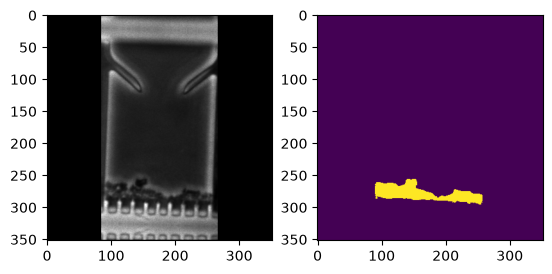

In [ ]:
# Test the dataset and transformations
phase, mask, scales = [], [], []
for d, nm, s in train_dirs:
    p, m = getTrainingPairs([(d, nm)])
    phase += p
    mask += m
    scales += [s] * len(p)
training_dataset = custom_loader_training(phase_ims = phase,
                                          mask_ims  = mask,
                                          scales = scales,
                                          transform = training_transform)

im, m = training_dataset[0]
fig,axs = plt.subplots(1,2)
axs[0].imshow(im.squeeze(),cmap='gray')
axs[1].imshow(m.squeeze())
print(f"Image mean: {im.mean():.4f}, std: {im.std():.4f}, min: {im.min():.4f}, max: {im.max():.4f}")

Number of phase images: 2523
Number of binary masks : 2523
training epoch 1
loss: 0.7565916073010823
training epoch 2
loss: 0.5478846128507918
training epoch 3
loss: 0.4156284436689703
training epoch 4
loss: 0.3227559543986785
training epoch 5
loss: 0.26332325437006643
training epoch 6
loss: 0.22900984022155793
training epoch 7
loss: 0.21387451044737302
training epoch 8
loss: 0.19786523344468618
training epoch 9
loss: 0.1861040413627432
training epoch 10
loss: 0.17786929959922393
training epoch 11
loss: 0.17729815010715833
training epoch 12
loss: 0.1684743872093758
training epoch 13
loss: 0.16661820424424215
training epoch 14
loss: 0.1681269553452376
training epoch 15
loss: 0.16616310826956235
training epoch 16
loss: 0.15623178605583105
training epoch 17
loss: 0.16219426797716183
training epoch 18
loss: 0.1598817011664429
training epoch 19
loss: 0.15400598398155385
training epoch 20
loss: 0.15515489635586455
training epoch 21
loss: 0.14847138754120914
training epoch 22
loss: 0.14447668

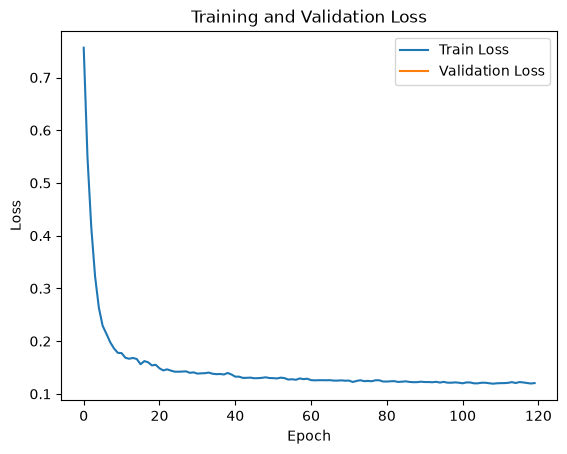

In [14]:
# Run training
train_net(train_dirs,save_dir, net_size=512, training_transform=training_transform, num_epochs=num_epochs, batch_size=batch_size, normalize=normalize)

Number of phase images: 1015
Number of binary masks : 1015
training epoch 1
loss: 0.880139383978731
training epoch 2
loss: 0.7287061173380829
training epoch 3
loss: 0.6727645721022538
training epoch 4
loss: 0.6031548822019982
training epoch 5
loss: 0.5541125041997339
training epoch 6
loss: 0.4907595911833245
training epoch 7
loss: 0.4453355802560416
training epoch 8
loss: 0.4026308733764596
training epoch 9
loss: 0.35611488458913143
training epoch 10
loss: 0.3276039098543445
training epoch 11
loss: 0.2956355402436782
training epoch 12
loss: 0.2776413880816595
training epoch 13
loss: 0.258343071625458
training epoch 14
loss: 0.26070207674202955
training epoch 15
loss: 0.23272621878019467
training epoch 16
loss: 0.21058453411215872
training epoch 17
loss: 0.1995558590283544
training epoch 18
loss: 0.19289854605953524
training epoch 19
loss: 0.19707884680567764
training epoch 20
loss: 0.19370773343706693
training epoch 21
loss: 0.18240070140619916
training epoch 22
loss: 0.174696098969090

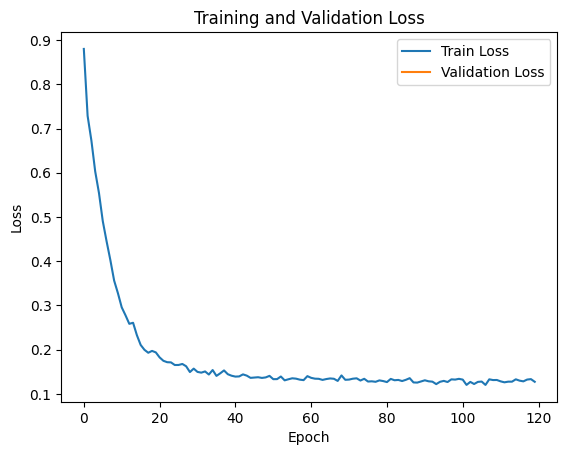

In [ ]:
#Train model only on the KI data for microchamber cell segmentation
# Set training parameters for cell segmentation, old parameters
train_dirs =[
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data','', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/KI_data_2','', 1.0),
                ]
save_dir = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769'
net_size = 256#512
batch_size = 4#8
#crop_h, crop_w = 144, 144 #176, 352
crop_window = 144#352
normalize = custom_normalize99
num_epochs = 120

training_transform = A.Compose(
    [
        A.GaussNoise(std_range=(2/225, 20/225), mean_range=(0, 0), p=0.5),
        A.Lambda(name='normalize', image=normalize, p=1.0),
        CellAwareCrop(p=1,crop_size=crop_window, min_cell_fraction=0.05, max_attempts=20),
        A.GridDistortion(p=0.4),
        A.Affine(p=0.8, translate_percent=(-0.2, 0.2), scale=(0.75, 1.25), rotate=(-5, 5)),
        A.GaussianBlur(p=0.6, blur_limit=0, sigma_limit=(0.1, 2.0)),
        A.GridDropout(p=0.3, ratio=0.3, random_offset=True),
        A.Lambda(name='to_tensor', image=custom_to_tensor, mask=custom_to_tensor, p=1.0)
    ]
    )


# Run training
train_net(train_dirs,save_dir, net_size=net_size, training_transform=training_transform, 
          num_epochs=num_epochs, batch_size=batch_size, normalize=normalize)

In [154]:
from skimage.transform import resize, rescale

def pad_image(img, pad=16):
    x,y = np.shape(img)
    xpad, ypad = 0, 0
    if x%pad != 0:
        xpad = pad-(x%pad)
    if y%pad != 0:
        ypad = pad-(y%pad)    
    padded_img = np.pad(img, ((0,xpad),(0,ypad)),'constant',constant_values=(0,0))
    return padded_img, x, y

def resize_image(img,scale=0.5):
    return rescale(img,scale,mode='constant',clip=True,preserve_range=True,anti_aliasing=True).astype(img.dtype)

def resize_mask(img,shape):
    return resize(img,shape,order=0,mode='constant',preserve_range=True,anti_aliasing=False).astype(img.dtype)

def custom_normalize99(image, lower=0.01, upper=99.99):
    #print(image.dtype)
    image = np.array(image).astype(np.float32)
    image_copy = image.copy()
    return np.interp(image_copy, 
                     (np.percentile(image_copy, lower), np.percentile(image_copy, upper)), (0, 1)).astype(np.float32)

def custom_normalize(image):
    img = img.astype('float32')
    mean = np.mean(image)
    std = np.std(image)
    if std < 1e-6:                          # guard against flat/empty patches
        return np.zeros_like(image, dtype=np.float32)
    return ((image - mean) / std).astype(np.float32)

def segment_unet(img, model, threshold=0.5, min_size=100, normalize=custom_normalize):
    
    img, xorg, yorg = pad_image(img)
    
    img = normalize(img).astype('float32')
    #img = (img - np.mean(img)) / np.std(img)
    img = torch.from_numpy(img).unsqueeze(0).unsqueeze(0).cuda()
    res = model(img)
    res = torch.sigmoid(res)
    res = res.to("cpu").detach().numpy().squeeze(0).squeeze(0)
    
    res = res[0:xorg,0:yorg]
    mask = res > threshold
    #mask = remove_small_objects(mask,max_size=min_size)

    mask = mask.astype('uint8')
    return mask

In [ ]:
# Validate masks
trap_net = UNet(max_filters = 512)
NET_PATH = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/models/unetTB_512_260930_122556.pth'
saved_net = torch.load(NET_PATH)
trap_net.load_state_dict(saved_net['model_state_dict']);
trap_net.eval();
trap_net.cuda();

images,_ = getTrainingPairs([train_dirs[4]])
res_dir = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/cell_masks_512_260930_122556'
import os
os.makedirs(res_dir,exist_ok=True)
with torch.no_grad():
    for fi, f in enumerate(images):
        im = io.imread(f)
        filename = f.split('/')[-1]
        mask = segment_unet(im,model=trap_net,threshold=0.5,normalize=normalize)
        fname = res_dir+'/'+filename
        imwrite(fname,mask, compression='zlib', compressionargs={'level':6})